# Лабораторная работа 14. AE VAE GAN
Выполните короткий опыт на 512 обучающих и 128 тестовых изображениях. Изменяйте число эпох после воспроизведения. Для полного протокола используйте команду из лабораторной работы.

In [1]:
from pathlib import Path
import os, sys
from tempfile import gettempdir
here=Path.cwd().resolve()
candidates=[entry for parent in (here,*here.parents) for entry in (parent,parent/'Deep_Learning_Textbook')]
book=next(entry for entry in candidates if (entry/'Python_Code/Chapter_14').is_dir())
sys.path.insert(0,str(book/'Python_Code/Chapter_14'))
import torch
from mini_generative import fashion_data,train_models,evaluate,prior_samples,kl_per_image,report
from generative_numeric import check_examples
torch.set_num_threads(2)
check_examples()
directory=Path(os.environ.get('FASHION_MNIST_DIR',Path(gettempdir())/'dl02-fashion-official'))
print('Данные',directory)

z=[[2.0, -1.0]] KL=1.750000 triplet=0.160000
D=0.255413 G=1.386294 dG/dlogit=-0.750000
Данные <локальный каталог>


In [2]:
train,test=fashion_data(directory,n_train=512,n_test=128,seed=2026)
ae,vae,gen,history=train_models(train,epochs=1,seed=2026)
result=evaluate(ae,vae,test)
report(history,result)
print('short train=512 test=128 epochs=1')

epoch=1 recon_bce=541.215881 kl=0.581860 discriminator=0.602430 generator=1.108935 ae_mse=0.170090
held_out vae_mu_mse=0.161145 vae_mu_bce=532.078796 vae_kl=1.454390 ae_mse=0.160713
short train=512 test=128 epochs=1


In [3]:
with torch.no_grad():
    mu,s=vae.posterior(test)
    direct=0.5*(mu.square()+s.exp()-1-s).sum(dim=1)
    torch.testing.assert_close(direct,kl_per_image(mu,s))
    vae_images,gan_images=prior_samples(vae,gen,n=8,latent=12,seed=55)
    assert vae_images.shape==gan_images.shape==(8,784)
    assert torch.isfinite(vae_images).all() and torch.isfinite(gan_images).all()
print('KL independently verified; two prior batches are finite')

KL independently verified; two prior batches are finite


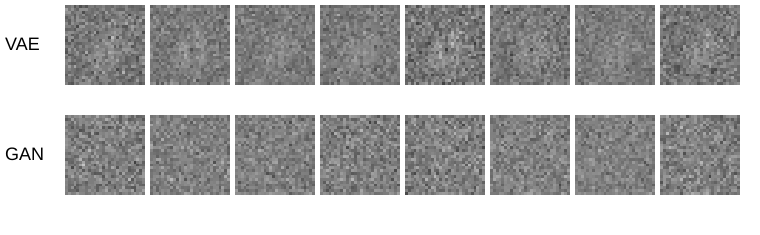

In [4]:
import base64
from io import BytesIO
from PIL import Image
from IPython.display import SVG,display

pieces=['<svg xmlns="http://www.w3.org/2000/svg" xmlns:xlink="http://www.w3.org/1999/xlink" width="760" height="235"><rect width="100%" height="100%" fill="white"/>']
for row,(name,values) in enumerate((('VAE',vae_images),('GAN',gan_images))):
    pieces.append(f'<text x="5" y="{50+row*110}" font-family="Arial" font-size="18">{name}</text>')
    for col,value in enumerate(values):
        array=value.reshape(28,28).clamp(0,1).mul(255).round().to(torch.uint8).numpy()
        image=Image.fromarray(array,mode='L')
        buffer=BytesIO();image.save(buffer,format='PNG')
        uri='data:image/png;base64,'+base64.b64encode(buffer.getvalue()).decode()
        pieces.append(f'<image x="{65+col*85}" y="{5+row*110}" width="80" height="80" style="image-rendering:pixelated" xlink:href="{uri}"/>')
pieces.append('</svg>')
display(SVG(''.join(pieces)))

## Задания
Сравните реконструкционную MSE и prior-панели. Повторите опыт с beta=0.1 и beta=4 на тех же данных. Зафиксируйте, какие свойства меняются. Не используйте тренировочные потери GAN как единственную оценку качества.